Trial 30 Complete [00h 00m 04s]
val_accuracy: 0.8435373902320862

Best val_accuracy So Far: 0.8707482814788818
Total elapsed time: 00h 01m 24s


Optimal Settings:
- Layers: 2
- Learning Rate: 0.01

Epoch 1/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.7551 - loss: 0.4727 - val_accuracy: 0.8299 - val_loss: 0.3956
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8755 - loss: 0.2883 - val_accuracy: 0.8435 - val_loss: 0.4242
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8857 - loss: 0.2937 - val_accuracy: 0.8435 - val_loss: 0.4086
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.8631 - loss: 0.2976 - val_accuracy: 0.8571 - val_loss: 0.4362
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step


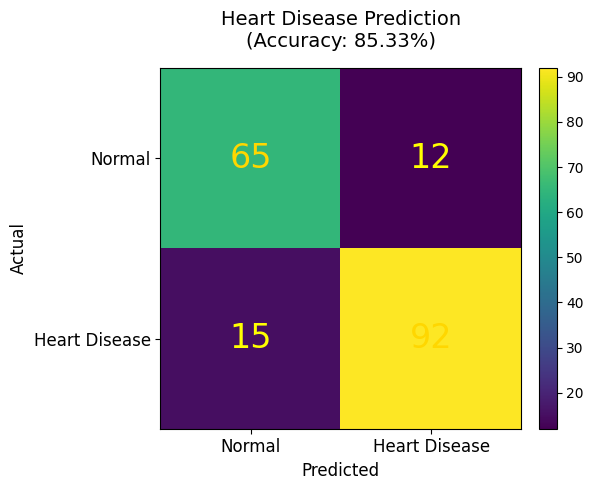


--- Classification Report ---
               precision    recall  f1-score   support

       Normal       0.81      0.84      0.83        77
Heart Disease       0.88      0.86      0.87       107

     accuracy                           0.85       184
    macro avg       0.85      0.85      0.85       184
 weighted avg       0.85      0.85      0.85       184



In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import keras_tuner as kt

dataset_path = "/kaggle/input/heart-failure-prediction"
files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]
df = pd.read_csv(os.path.join(dataset_path, files[0]))

print(f"Dataset Loaded. Rows: {df.shape[0]}, Columns: {df.shape[1]}")

zero_count = (df['FastingBS'] == 0).sum()
print(f"FastingBS has {zero_count} zeros out of {len(df)} rows.")

# filtering
# We drop 'FastingBS' as per your request (filtering out less useful features)
# We also drop the Target column from features
features_to_drop = ['HeartDisease', 'FastingBS'] 
X = df.drop(columns=features_to_drop, errors='ignore')
y = df['HeartDisease'] # This is the "Teacher" (0 or 1)

print(f"\nTraining with Features: {X.columns.tolist()}")

#preprocessing
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

# Build Preprocessor
# StandardScale for numbers (Age, BP, Cholesterol)
# OneHotEncode for categories (Sex, ChestPain, RestingECG)
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
    ])

X_processed = preprocessor.fit_transform(X)

#split Data
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42)

#ensure Dense Array
if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()
    X_test = X_test.toarray()


#fine tuning
def build_model(hp):
    model = keras.Sequential()
    model.add(layers.InputLayer(input_shape=(X_train.shape[1],)))
    
    #tune Number of Layers and Neurons
    #we allow the tuner to choose between 1, 2, or 3 hidden layers
    for i in range(hp.Int('num_layers', 1, 3)):
        model.add(layers.Dense(
            units=hp.Int(f'units_{i}', min_value=16, max_value=128, step=16),
            activation='relu'
        ))
        # Optional Dropout
        if hp.Boolean("dropout"):
            model.add(layers.Dropout(0.3))
    
    # outut layer
    # Binary Classification (2 classes) -> 1 Neuron with Sigmoid
    # Sigmoid outputs a probability between 0 and 1
    model.add(layers.Dense(1, activation='sigmoid'))
    
    # Tune Learning Rate
    hp_lr = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=hp_lr),
        loss='binary_crossentropy', # Standard loss for 2 classes
        metrics=['accuracy']
    )
    return model

#initialize tuner
tuner = kt.Hyperband(
    build_model,
    objective='val_accuracy',
    max_epochs=15,
    factor=3,
    directory='heart_tuning',
    project_name='heart_disease_v1'
)

stop_early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3)

print("\n--- Starting Hyperparameter Search ---")
tuner.search(X_train, y_train, epochs=20, validation_split=0.2, callbacks=[stop_early], verbose=1)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

print(f"""
\nOptimal Settings:
- Layers: {best_hps.get('num_layers')}
- Learning Rate: {best_hps.get('learning_rate')}
""")

#train the final model
model = tuner.hypermodel.build(best_hps)

history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[stop_early],
    verbose=1
)

#visualization of data
def plot_custom_matrix(y_true, y_pred_probs, title):
    # Convert probability to class (Threshold 0.5)
    # If prob > 0.5 -> Class 1 (Disease), else Class 0 (Normal)
    y_pred = (y_pred_probs > 0.5).astype(int).flatten()
    
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, interpolation='nearest', cmap='viridis')
    plt.colorbar(im, fraction=0.046, pad=0.04)
    
    ax.set_title(f"{title}\n(Accuracy: {acc*100:.2f}%)", fontsize=14, pad=15)
    
    # Labels for Binary Classification
    labels = ['Normal', 'Heart Disease']
    tick_marks = np.arange(len(labels))
    ax.set_xticks(tick_marks)
    ax.set_yticks(tick_marks)
    ax.set_xticklabels(labels, fontsize=12)
    ax.set_yticklabels(labels, fontsize=12)
    
    ax.set_xlabel('Predicted', fontsize=12)
    ax.set_ylabel('Actual', fontsize=12)
    
    # Add numbers to squares
    thresh = cm.max() / 2.
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, format(cm[i, j], 'd'),
                    ha="center", va="center",
                    fontsize=24, 
                    color="yellow" if cm[i, j] < thresh else "gold")
    
    plt.tight_layout()
    plt.show()

# Predict
y_test_probs = model.predict(X_test)

# Plot
plot_custom_matrix(y_test, y_test_probs, "Heart Disease Prediction")

print("\n--- Classification Report ---")
y_pred_final = (y_test_probs > 0.5).astype(int).flatten()
print(classification_report(y_test, y_pred_final, target_names=['Normal', 'Heart Disease']))